# Tabular — Deep Learning (Regresi, MLP PyTorch)
**Kapan dipakai:** ingin mencoba neural network untuk menebak angka di data tabel.
Biasanya LightGBM lebih kuat di tabel, tapi MLP berguna untuk ensembling.

**Langkah:**
1. Kolom disiapkan dengan sklearn. Kolom angka dibuat berdistribusi normal
   (QuantileTransformer) karena neural network suka angka di sekitar 0.
2. Target dilatih dalam skala log (`log1p`), lalu dikembalikan (`expm1`) saat menebak.
3. MLP dilatih dengan PyTorch, per batch.

**Data demo:** Diamonds (target `price`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer
from torch import nn

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/tabular/regression"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/diamonds_train.csv"
TEST_CSV = f"{DATA_FOLDER}/diamonds_test.csv"

TARGET = "price"
NUM_COLS = ["carat", "depth", "table", "x", "y", "z"]
CAT_COLS = ["cut", "color", "clarity"]
EPOCHS = 60              # berapa kali seluruh data train dilihat model
BATCH_SIZE = 256         # jumlah baris per langkah belajar
LEARNING_RATE = 1e-3
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (4800, 11) | test: (1200, 10)


,id,carat,cut,color,clarity,depth,table,price,x,y,z
0,3898,0.37,Premium,F,VS2,61.0,58.0,957,4.63,4.61,2.82
1,5629,0.40,Very Good,D,VS2,63.5,55.0,952,4.69,4.66,2.97
2,1757,0.31,Premium,G,IF,61.0,59.0,988,4.36,4.33,2.65
3,2347,0.31,Ideal,E,SI1,63.0,57.0,698,4.32,4.29,2.71
4,2997,0.54,Ideal,G,VS1,61.0,57.0,1957,5.25,5.28,3.21


## Split + siapkan kolom
PyTorch butuh angka float32, jadi hasil `preprocess` diubah dengan `.astype(np.float32)`.

In [4]:
X = train[NUM_COLS + CAT_COLS]
y = train[TARGET].values
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=SEED)

num_steps = make_pipeline(SimpleImputer(strategy="median"),
                          QuantileTransformer(output_distribution="normal"))
cat_steps = make_pipeline(SimpleImputer(strategy="most_frequent"),
                          OneHotEncoder(handle_unknown="ignore", sparse_output=False))
preprocess = ColumnTransformer([
    ("num", num_steps, NUM_COLS),
    ("cat", cat_steps, CAT_COLS),
])
X_train_ready = preprocess.fit_transform(X_train).astype(np.float32)
X_val_ready = preprocess.transform(X_val).astype(np.float32)

N_FEATURES = X_train_ready.shape[1]
print(N_FEATURES, "feature")

26 feature


## Model
`make_model()` membuat MLP baru (bobot acak). Output 1 angka = tebakan log(harga).
Pilih SATU `return`: hapus `#` di blok yang ingin dipakai, beri `#` pada blok lain.

In [5]:
def make_model():
    return nn.Sequential(
        nn.Linear(N_FEATURES, 256), nn.ReLU(),
        nn.Linear(256, 128), nn.ReLU(),
        nn.Linear(128, 1),
    )
    # return nn.Sequential(nn.Linear(N_FEATURES, 64), nn.ReLU(), nn.Linear(64, 1))
    # return nn.Sequential(
    #     nn.Linear(N_FEATURES, 512), nn.BatchNorm1d(512), nn.ReLU(), nn.Dropout(0.1),
    #     nn.Linear(512, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.1),
    #     nn.Linear(256, 1),
    # )


# coba: tampilkan susunan lapisan
print(make_model())

Sequential(
  (0): Linear(in_features=26, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=1, bias=True)
)


## Latih
Loss = MSE pada log(harga). `squeeze(1)` mengubah bentuk (n, 1) menjadi (n,).

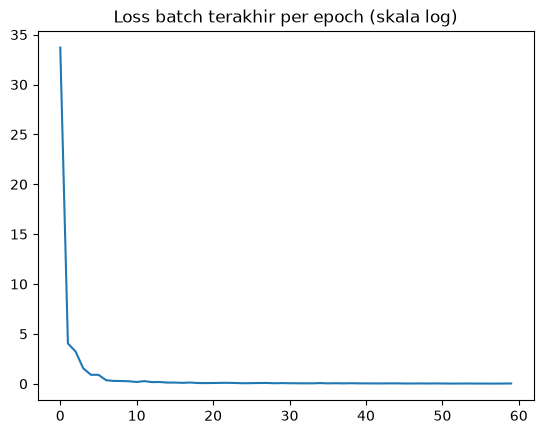

In [6]:
def train_model(X_ready, y_values):
    model = make_model().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    X_tensor = torch.tensor(X_ready, device=DEVICE)
    y_tensor = torch.tensor(np.log1p(y_values), dtype=torch.float32, device=DEVICE)
    loss_history = []
    for epoch in range(EPOCHS):
        model.train()
        order = torch.randperm(len(X_tensor), device=DEVICE)
        for i in range(0, len(X_tensor), BATCH_SIZE):
            batch = order[i:i + BATCH_SIZE]
            outputs = model(X_tensor[batch]).squeeze(1)
            loss = nn.functional.mse_loss(outputs, y_tensor[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        loss_history.append(loss.item())
    return model, loss_history


model, loss_history = train_model(X_train_ready, y_train)
plt.plot(loss_history)
plt.title("Loss batch terakhir per epoch (skala log)")
plt.show()

## Evaluasi di validasi

In [7]:
def predict_values(model, X_ready):
    model.eval()
    with torch.no_grad():
        log_predictions = model(torch.tensor(X_ready, device=DEVICE)).squeeze(1)
    log_predictions = log_predictions.cpu().numpy()
    return np.expm1(log_predictions)


val_predictions = predict_values(model, X_val_ready)
print("RMSE:", round(np.sqrt(mean_squared_error(y_val, val_predictions)), 2))
print("MAE :", round(mean_absolute_error(y_val, val_predictions), 2))
print("R2  :", round(r2_score(y_val, val_predictions), 4))

RMSE: 2137.32
MAE : 597.89
R2  : 0.7075


## Latih ulang di semua data + submission

In [8]:
X_all_ready = preprocess.fit_transform(X).astype(np.float32)
X_test_ready = preprocess.transform(test[NUM_COLS + CAT_COLS]).astype(np.float32)
model, loss_history = train_model(X_all_ready, y)
predictions = predict_values(model, X_test_ready)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["price"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,price
0,1783,3980.183105
1,3918,5326.274414
2,222,2858.243896
3,2136,15687.715820
4,5225,881.451965
